# Milestone 2: Fairness and Business Value
**FEMA Individuals & Households Program (IHP) registrations, Hurricane Ian (DR-4673), Lee County, FL**

**Team FEMA:** Anthony Stoneking, Daniel Ortiz, Nandor Laar
**Course:** CAI 4105 Machine Learning, Fall 2026

## Project Overview
The modeling notebook (`notebooks/modeling/01_model_comparison.ipynb`) compared ten algorithms and chose **gradient boosting** for both tiers.
This notebook takes that chosen model and asks three questions that an accuracy score cannot answer:

1. **Is it fair?** Does the model make more mistakes for some age groups or income groups than for others?
2. **Who is in the "not eligible" group?** Our label mixes people who were turned down with people who never finished the process. Which of them does the model get wrong?
3. **What is it worth?** What do the model's mistakes mean in numbers of households, and how could FEMA use the predictions?

## How to run
Put `ihp_dr4673_lee.csv` in `data/raw/` (or next to this notebook) and choose **Restart & Run All**. It takes about two minutes.

## How this notebook is organized
- **Part 1:** setup, and the same data preparation and split as the modeling notebook, so both notebooks score the same applicants
- **Part 2:** fairness by age group and income group
- **Part 3:** who is in the "not eligible" group
- **Part 4:** business value
- **Part 5:** summary against our success criteria

`REPORT_SPLIT` (below) decides which applicants are scored. It stays on the **validation** set until the team freezes the model, then it is switched to the **test** set once.

---
# Part 1: Setup and Data Preparation

## Import Required Libraries

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.ensemble import HistGradientBoostingClassifier

warnings.filterwarnings("ignore")

RANDOM_STATE = 42        # same seed as the modeling notebook, so the split is identical
REPORT_SPLIT = "val"     # "val" until the model freeze, then "test" (used once)
FAIRNESS_LIMIT = 0.05    # Milestone 1 target: no group more than 5 percentage points above the overall error rate
MIN_GROUP_ROWS = 100     # groups smaller than this are shown but not judged

## Chart style
Same colors as the modeling notebook.

In [2]:
BLUE = "#2a78d6"    # Tier 1 / main series
AQUA = "#1baf7a"    # Tier 2
ORANGE = "#eb6834"  # over the limit / not eligible
GRAY = "#898781"
INK, INK_SOFT, GRID = "#0b0b0b", "#52514e", "#e1e0d9"
TIER_COLORS = {"application": BLUE, "inspection": AQUA}
TIER_NAMES = {"application": "Tier 1 (application)", "inspection": "Tier 2 (inspection)"}

# Find the project folder, so figures land in reports/figures no matter where the notebook is run from
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").exists()), Path.cwd())
FIG_DIR = ROOT / "reports" / "figures"

plt.rcParams.update({
    "figure.figsize": (8, 4.5), "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans", "Arial"], "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK_SOFT, "axes.edgecolor": GRID, "axes.grid": True, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": INK_SOFT, "ytick.color": INK_SOFT, "text.color": INK, "legend.frameon": False,
    "lines.linewidth": 2,
})


def save_fig(name):
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    plt.savefig(FIG_DIR / f"m2_fair_{name}.png")


def tick_labels(index):
    # matplotlib reads "$" as the start of a math formula, so income labels need it escaped
    return [str(v).replace("$", r"\$") for v in index]


LABEL_BOX = dict(facecolor="white", edgecolor="none", pad=1.5, alpha=0.9)   # keeps value labels readable over lines

## Load the data

In [3]:
CSV_NAME = "ihp_dr4673_lee.csv"
CSV_CANDIDATES = [Path(CSV_NAME), ROOT / "data" / "raw" / CSV_NAME]


def load_data():
    for path in CSV_CANDIDATES:
        if path.exists():
            return pd.read_csv(path, low_memory=False)
    raise FileNotFoundError(f"Put {CSV_NAME} in data/raw/ or in the same folder as this notebook.")


raw = load_data()
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns")

194,482 rows x 100 columns


## Same features, cleaning, split, and preprocessing as the modeling notebook
The next four cells are copied from `01_model_comparison.ipynb` without changes.
They must stay identical: the same seed and the same steps give the same training, validation, and test rows, so the fairness results describe the same model the team selected.

In [4]:
TARGET = "ihpEligible"

# Tier 1: known at registration (self-reported)
APPLICATION_FEATURES = [
    "appliedDate", "applicantAge", "householdComposition",
    "occupantsUnderTwo", "occupants2to5", "occupants6to18", "occupants19to64", "occupants65andOver",
    "grossIncome", "ownRent", "primaryResidence", "residenceType",
    "homeOwnersInsurance", "floodInsurance", "registrationMethod",
    "damagedZipCode", "censusGeoid",
    "homeDamage", "autoDamage", "reportedDamage", "selfAssessmentInformation",
    "emergencyNeeds", "foodNeed", "shelterNeed", "accessFunctionalNeeds",
]
# Tier 2: only known after a FEMA inspection or verification step
INSPECTION_FEATURES = [
    "inspnIssued", "inspnReturned", "rpfvl", "ppfvl",
    "floodDamage", "floodDamageAmount", "waterLevel", "highWaterLocation",
    "destroyed", "renterDamageLevel", "verifiedOwnership", "verifiedOccupancy",
    "habitabilityRepairsRequired", "currentLocation",
]
TIERS = {"application": APPLICATION_FEATURES, "inspection": APPLICATION_FEATURES + INSPECTION_FEATURES}

# ineligibleReason is a RESULT of FEMA's decision. It is never a model input.
# This notebook only uses it afterwards, to describe who the model got wrong (Part 3).
assert "ineligibleReason" not in TIERS["inspection"]

In [5]:
LANDFALL = pd.Timestamp("2022-09-28")
AGE_ORDER = {"<19": 0, "19-34": 1, "35-49": 2, "50-64": 3, "65+": 4}
COUNT_ORDER = {"0": 0, "1": 1, "2": 2, "3": 3, "4": 4, "5": 5, ">5": 6}
COUNT_COLS = ["householdComposition", "occupantsUnderTwo", "occupants2to5",
              "occupants6to18", "occupants19to64", "occupants65andOver"]
CATEGORICAL_COLS = ["grossIncome", "ownRent", "residenceType", "registrationMethod", "currentLocation",
                    "selfAssessmentInformation", "damagedZipCode", "censusGeoid",
                    "highWaterLocation", "renterDamageLevel"]


def clean(raw, tier):
    df = raw[[TARGET] + TIERS[tier]].copy()
    df[TARGET] = df[TARGET].astype(int)

    applied = pd.to_datetime(df.pop("appliedDate"), utc=True).dt.tz_localize(None)
    df["daysSinceLandfall"] = (applied - LANDFALL).dt.days

    df["applicantAge"] = df["applicantAge"].map(AGE_ORDER)
    for c in COUNT_COLS:
        df[c] = df[c].astype(str).map(COUNT_ORDER)

    for c in df.columns:
        values = df[c].dropna()
        if c != TARGET and len(values) and values.map(type).eq(bool).all():
            df[c] = df[c].map({True: 1.0, False: 0.0})

    for c in CATEGORICAL_COLS:
        if c in df.columns:
            df[c] = df[c].map(lambda v: v if pd.isna(v) else str(v)).astype(object)
    return df


tables = {tier: clean(raw, tier) for tier in TIERS}

In [6]:
idx_trainval, idx_test = train_test_split(
    tables["application"].index, test_size=0.20, stratify=tables["application"][TARGET], random_state=RANDOM_STATE)
idx_train, idx_val = train_test_split(
    idx_trainval, test_size=0.25, stratify=tables["application"].loc[idx_trainval, TARGET], random_state=RANDOM_STATE)
SPLIT_INDEX = {"train": idx_train, "val": idx_val, "test": idx_test}

DATA = {}
for tier, df in tables.items():
    X, y = df.drop(columns=TARGET), df[TARGET]
    DATA[tier] = {name: (X.loc[idx], y.loc[idx]) for name, idx in SPLIT_INDEX.items()}

pd.DataFrame({
    name: {"rows": len(idx), "share eligible": tables["application"].loc[idx, TARGET].mean().round(3)}
    for name, idx in SPLIT_INDEX.items()
}).T

,rows,share eligible
train,116688.0,0.507
val,38897.0,0.507
test,38897.0,0.507


In [7]:
PLACE_COLS = ["damagedZipCode", "censusGeoid"]
SKEWED_COLS = ["rpfvl", "ppfvl", "floodDamageAmount", "waterLevel"]


class FrequencyEncoder(BaseEstimator, TransformerMixin):
    # Replace each code with the number of training rows that have it (unseen codes get 0).

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.counts_ = {c: X[c].value_counts() for c in X.columns}
        return self

    def transform(self, X):
        X = pd.DataFrame(X)
        return np.column_stack([X[c].map(self.counts_[c]).fillna(0).astype(float) for c in X.columns])

    def get_feature_names_out(self, input_features=None):
        return np.asarray(list(self.counts_), dtype=object)


def make_preprocessor(X):
    place = [c for c in PLACE_COLS if c in X.columns]
    skewed = [c for c in SKEWED_COLS if c in X.columns]
    categorical = [c for c in X.columns if X[c].dtype == object and c not in place]
    numeric = [c for c in X.columns if c not in place + skewed + categorical]
    return ColumnTransformer([
        ("numeric", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), numeric),
        ("skewed", make_pipeline(SimpleImputer(strategy="median"), FunctionTransformer(np.log1p, feature_names_out="one-to-one"), StandardScaler()), skewed),
        ("place", make_pipeline(FrequencyEncoder(), FunctionTransformer(np.log1p, feature_names_out="one-to-one"), StandardScaler()), place),
        ("categorical", make_pipeline(SimpleImputer(strategy="constant", fill_value="missing"),
                                      OneHotEncoder(handle_unknown="ignore", sparse_output=False)), categorical),
    ])

## Refit the chosen model
The modeling notebook selected **gradient boosting** for both tiers and found its best settings with a 5-fold grid search.
We do not repeat the search here. We refit the model once per tier with those winning settings, on the same training rows.

The check table compares our validation AUC with the one reported in the modeling notebook. They should agree to about two decimals. If they do not, the two notebooks are not scoring the same model and the results below should not be used.

In [8]:
# Best settings and validation AUC, copied from the "Gradient boosting" results table in 01_model_comparison.ipynb
BEST_SETTINGS = {
    "application": {"learning_rate": 0.1, "max_leaf_nodes": 63},
    "inspection": {"learning_rate": 0.05, "max_leaf_nodes": 63},
}
MODELING_NOTEBOOK_VAL_AUC = {"application": 0.880, "inspection": 0.938}

MODELS = {}
check = []
for tier in TIERS:
    X_tr, y_tr = DATA[tier]["train"]
    X_va, y_va = DATA[tier]["val"]
    model = Pipeline([
        ("prep", make_preprocessor(X_tr)),
        ("model", HistGradientBoostingClassifier(max_iter=500, early_stopping=True, random_state=RANDOM_STATE,
                                                 **BEST_SETTINGS[tier])),
    ]).fit(X_tr, y_tr)
    MODELS[tier] = model
    auc = roc_auc_score(y_va, model.predict_proba(X_va)[:, 1])
    check.append({"tier": TIER_NAMES[tier], "validation AUC here": round(auc, 3),
                  "modeling notebook": MODELING_NOTEBOOK_VAL_AUC[tier],
                  "difference": round(auc - MODELING_NOTEBOOK_VAL_AUC[tier], 3)})

pd.DataFrame(check).set_index("tier")

,validation AUC here,modeling notebook,difference
tier,,,
Tier 1 (application),0.880,0.880,0.0
Tier 2 (inspection),0.938,0.938,0.0


## One table of predictions
Everything after this cell reads from `pred`: one row per applicant in the reporting split, for each tier.
The group labels (age band, income band, FEMA's reason code) are taken from the raw data. They are used to *describe* the predictions, not to make them.

In [9]:
AGE_BANDS = ["<19", "19-34", "35-49", "50-64", "65+"]
INCOME_BANDS = ["0", "<$15,000", "$15,000-$30,000", "$30,001-$60,000",
                "$60,001-$120,000", "$120,001-$175,000", ">$175,000"]
INCOME_LABELS = {"0": "0 (none reported)"}
REASONS = {
    1: "No eligible damage or needs",
    2: "Has insurance",
    3: "Did not respond or withdrew",
    4: "Needs to submit documentation",
    5: "Duplicate application",
    6: "Flood zone reason",
    7: "Other",
    8: "Pending",
    9: "Other (not identified)",
}
UNFINISHED_REASONS = ["Did not respond or withdrew", "Needs to submit documentation"]

idx = SPLIT_INDEX[REPORT_SPLIT]
parts = []
for tier in TIERS:
    X, y = DATA[tier][REPORT_SPLIT]
    prob = MODELS[tier].predict_proba(X)[:, 1]
    part = pd.DataFrame({"tier": tier, "y_true": y.values, "prob": prob}, index=idx)
    part["y_pred"] = (part["prob"] >= 0.5).astype(int)
    part["age"] = pd.Categorical(raw.loc[idx, "applicantAge"], categories=AGE_BANDS, ordered=True)
    income = raw.loc[idx, "grossIncome"].astype(str)
    part["income"] = pd.Categorical(income, categories=INCOME_BANDS, ordered=True).rename_categories(INCOME_LABELS)
    part["reason"] = raw.loc[idx, "ineligibleReason"].map(REASONS)
    part.loc[(part["y_true"] == 0) & part["reason"].isna(), "reason"] = "Never referred to the program"
    parts.append(part)
pred = pd.concat(parts)
pred["error"] = (pred["y_true"] != pred["y_pred"]).astype(int)

SPLIT_LABEL = {"val": "validation set", "test": "test set"}[REPORT_SPLIT]
print(f"Scoring the {SPLIT_LABEL}: {len(idx):,} applicants per tier")
pred.head()

Scoring the validation set: 38,897 applicants per tier


,tier,y_true,prob,y_pred,age,income,reason,error
79402,application,0,0.649330,1,50-64,"$60,001-$120,000",Has insurance,1
128085,application,0,0.551875,1,19-34,"$30,001-$60,000",No eligible damage or needs,1
2345,application,1,0.604038,1,19-34,"$30,001-$60,000",NaN,0
64933,application,1,0.604960,1,50-64,"$15,000-$30,000",NaN,0
121841,application,0,0.002936,0,35-49,"$15,000-$30,000",Never referred to the program,0


---
# Part 2: Fairness by Age Group and Income Group

**What we measure.** For each group we count the model's mistakes and split them into the two kinds, because they hurt different people:
- **Missed eligible** (false negative rate): of the households that *did* receive aid, the share the model predicted would not. In a triage tool these are the households at risk of being pushed to the back of the queue.
- **Wrongly predicted eligible** (false positive rate): of the households that did *not* receive aid, the share the model predicted would.

**Our target from Milestone 1:** no group's error rate is more than 5 percentage points above the overall error rate.

Age and income are also inputs to the model. That is allowed here because FEMA collects them on the application, but it is exactly why we check that the model does not perform worse for any one band.

In [10]:
def rates(df):
    # Error rates for one group of predictions.
    elig, not_elig = df[df.y_true == 1], df[df.y_true == 0]
    return pd.Series({
        "applicants": len(df),
        "share eligible": df.y_true.mean(),
        "predicted eligible": df.y_pred.mean(),
        "error rate": df.error.mean(),
        "missed eligible (FNR)": (elig.y_pred == 0).mean() if len(elig) else np.nan,
        "wrongly eligible (FPR)": (not_elig.y_pred == 1).mean() if len(not_elig) else np.nan,
    })


def group_table(tier, column):
    df = pred[pred.tier == tier]
    overall = rates(df)
    table = df.groupby(column, observed=False).apply(rates)
    table.loc["All applicants"] = overall
    table["gap vs overall"] = table["error rate"] - overall["error rate"]
    table["within target"] = np.where(table["applicants"] < MIN_GROUP_ROWS, "too few rows",
                                      np.where(table["gap vs overall"] <= FAIRNESS_LIMIT, "yes", "NO"))
    table["applicants"] = table["applicants"].astype(int)
    return table


FAIR = {(tier, col): group_table(tier, col) for tier in TIERS for col in ["age", "income"]}

for (tier, col), table in FAIR.items():
    print(f"{TIER_NAMES[tier]}, by {col} group ({SPLIT_LABEL})")
    display(table.round(3))

Tier 1 (application), by age group (validation set)


,applicants,share eligible,predicted eligible,error rate,missed eligible (FNR),wrongly eligible (FPR),gap vs overall,within target
age,,,,,,,,
<19,237,0.295,0.203,0.228,0.543,0.096,0.038,yes
19-34,6852,0.518,0.622,0.237,0.128,0.355,0.047,yes
35-49,9877,0.500,0.589,0.214,0.125,0.302,0.023,yes
50-64,11490,0.486,0.535,0.177,0.132,0.220,-0.013,yes
65+,10441,0.536,0.564,0.150,0.114,0.192,-0.040,yes
All applicants,38897,0.507,0.570,0.190,0.126,0.256,0.000,yes


Tier 1 (application), by income group (validation set)


,applicants,share eligible,predicted eligible,error rate,missed eligible (FNR),wrongly eligible (FPR),gap vs overall,within target
income,,,,,,,,
0 (none reported),8751,0.419,0.464,0.186,0.168,0.199,-0.004,yes
"<$15,000",2661,0.607,0.713,0.231,0.103,0.429,0.041,yes
"$15,000-$30,000",6042,0.585,0.681,0.218,0.104,0.378,0.028,yes
"$30,001-$60,000",10125,0.551,0.630,0.204,0.114,0.315,0.014,yes
"$60,001-$120,000",7722,0.480,0.524,0.162,0.123,0.198,-0.028,yes
"$120,001-$175,000",2019,0.445,0.457,0.153,0.158,0.149,-0.037,yes
">$175,000",1577,0.458,0.472,0.130,0.127,0.132,-0.060,yes
All applicants,38897,0.507,0.570,0.190,0.126,0.256,0.000,yes


Tier 2 (inspection), by age group (validation set)


,applicants,share eligible,predicted eligible,error rate,missed eligible (FNR),wrongly eligible (FPR),gap vs overall,within target
age,,,,,,,,
<19,237,0.295,0.308,0.165,0.257,0.126,0.035,yes
19-34,6852,0.518,0.647,0.180,0.049,0.321,0.051,NO
35-49,9877,0.500,0.615,0.160,0.044,0.275,0.031,yes
50-64,11490,0.486,0.558,0.115,0.045,0.182,-0.014,yes
65+,10441,0.536,0.573,0.081,0.041,0.127,-0.048,yes
All applicants,38897,0.507,0.591,0.129,0.045,0.216,0.000,yes


Tier 2 (inspection), by income group (validation set)


,applicants,share eligible,predicted eligible,error rate,missed eligible (FNR),wrongly eligible (FPR),gap vs overall,within target
income,,,,,,,,
0 (none reported),8751,0.419,0.491,0.126,0.065,0.171,-0.003,yes
"<$15,000",2661,0.607,0.716,0.161,0.043,0.343,0.032,yes
"$15,000-$30,000",6042,0.585,0.693,0.149,0.036,0.309,0.020,yes
"$30,001-$60,000",10125,0.551,0.649,0.141,0.040,0.266,0.012,yes
"$60,001-$120,000",7722,0.480,0.551,0.112,0.044,0.175,-0.017,yes
"$120,001-$175,000",2019,0.445,0.496,0.092,0.046,0.128,-0.038,yes
">$175,000",1577,0.458,0.490,0.067,0.039,0.090,-0.063,yes
All applicants,38897,0.507,0.591,0.129,0.045,0.216,0.000,yes


## Error rate for every group
Each dot is one group. The solid line is the overall error rate and the dashed line is our limit (overall + 5 percentage points). A dot to the right of the dashed line misses the target.

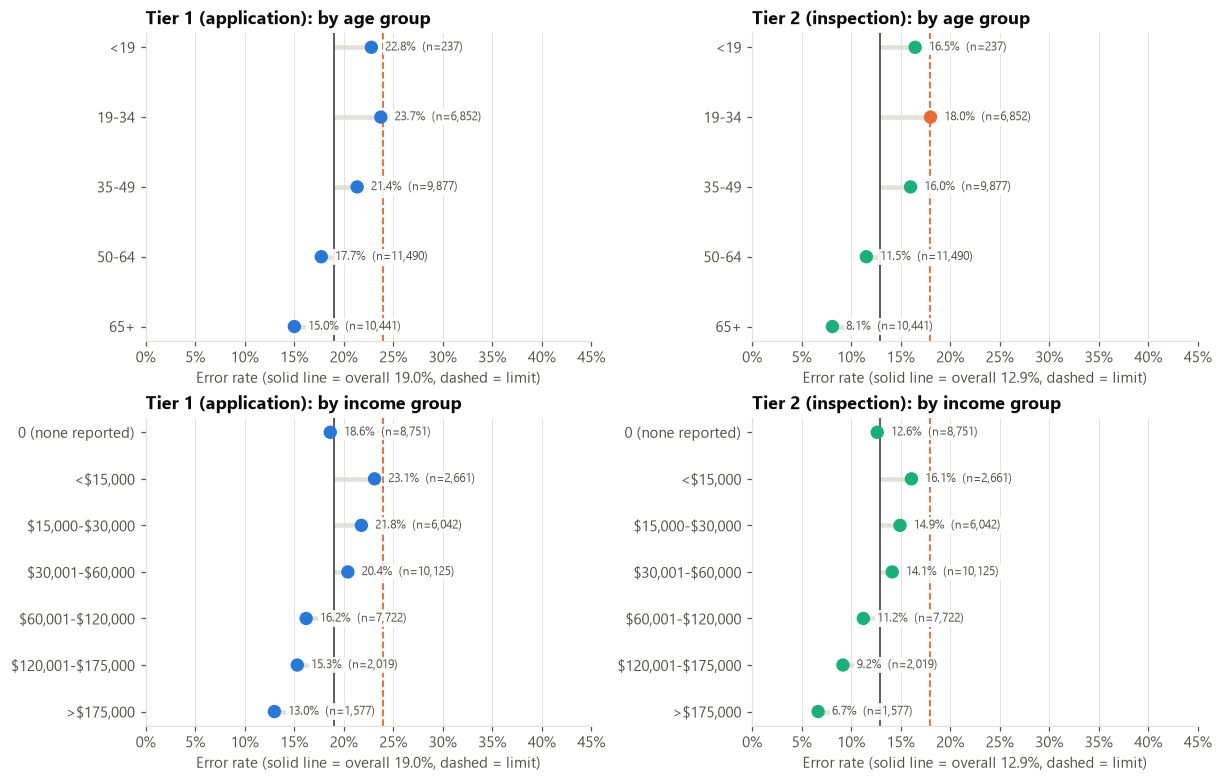

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), layout="constrained")
for row, col in enumerate(["age", "income"]):
    for ax, tier in zip(axes[row], TIERS):
        table = FAIR[(tier, col)]
        overall = table.loc["All applicants", "error rate"]
        groups = table.drop(index="All applicants")
        y = np.arange(len(groups))[::-1]
        over = groups["gap vs overall"] > FAIRNESS_LIMIT
        small = groups["applicants"] < MIN_GROUP_ROWS
        colors = np.where(small, GRAY, np.where(over, ORANGE, TIER_COLORS[tier]))
        ax.hlines(y, overall, groups["error rate"], color=GRID, lw=3, zorder=1)
        ax.scatter(groups["error rate"], y, s=60, c=list(colors), zorder=3)
        for yi, (name, g) in zip(y, groups.iterrows()):
            ax.annotate(f"{g['error rate']:.1%}  (n={int(g['applicants']):,})", (g["error rate"], yi),
                        xytext=(9, 0), textcoords="offset points", va="center", fontsize=8, color=INK_SOFT,
                        bbox=LABEL_BOX, zorder=4)
        ax.axvline(overall, color=INK_SOFT, lw=1.2)
        ax.axvline(overall + FAIRNESS_LIMIT, color=ORANGE, lw=1.2, ls="--")
        ax.set_yticks(y, tick_labels(groups.index))
        ax.set_xlim(0, max(0.45, groups["error rate"].max() + 0.12))
        ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
        ax.set_title(f"{TIER_NAMES[tier]}: by {col} group")
        ax.set_xlabel(f"Error rate (solid line = overall {overall:.1%}, dashed = limit)")
        ax.grid(axis="y", visible=False)
save_fig("error_rate_by_group")
plt.show()

## Which kind of mistake, for which group
The same groups, with the error split into its two kinds. A group can have an average error rate and still carry more of the mistake that hurts most.

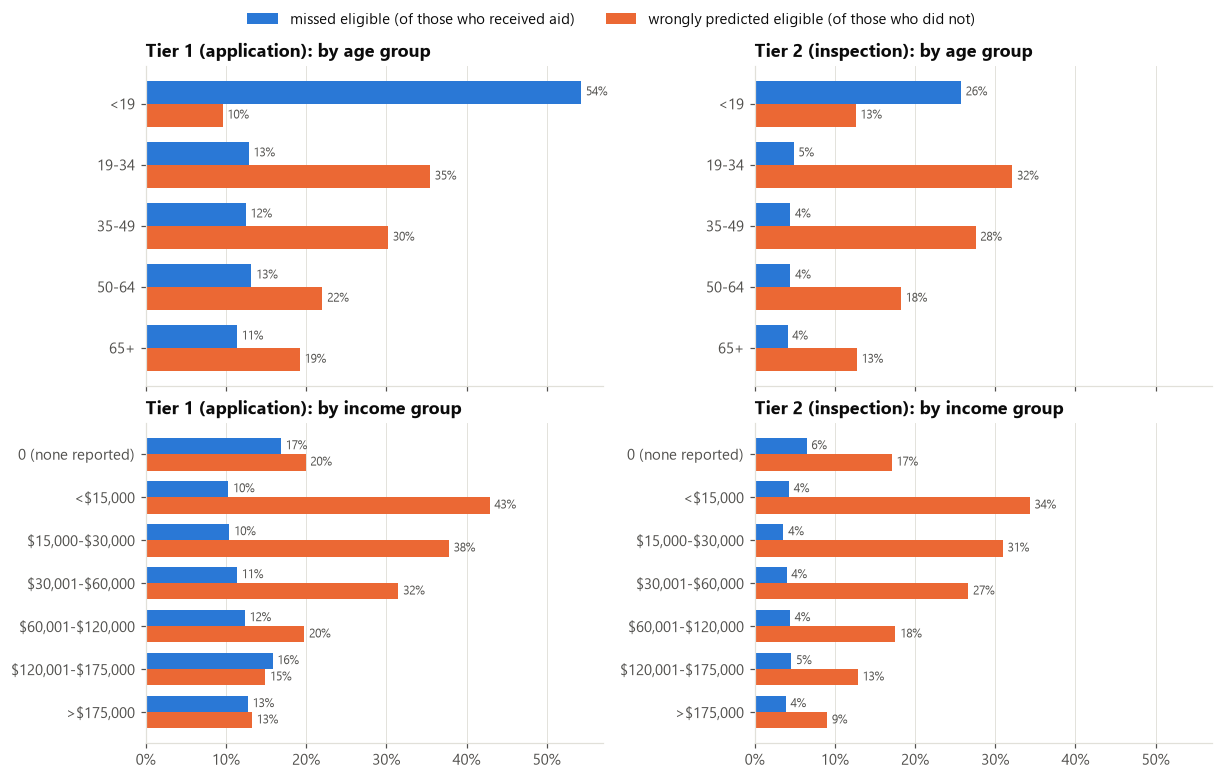

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), layout="constrained", sharex=True)
for row, col in enumerate(["age", "income"]):
    for ax, tier in zip(axes[row], TIERS):
        groups = FAIR[(tier, col)].drop(index="All applicants")
        y = np.arange(len(groups))[::-1]
        h = 0.38
        ax.barh(y + h / 2, groups["missed eligible (FNR)"], height=h, color=BLUE,
                label="missed eligible (of those who received aid)")
        ax.barh(y - h / 2, groups["wrongly eligible (FPR)"], height=h, color=ORANGE,
                label="wrongly predicted eligible (of those who did not)")
        for yi, (_, g) in zip(y, groups.iterrows()):
            ax.text(g["missed eligible (FNR)"] + 0.006, yi + h / 2, f"{g['missed eligible (FNR)']:.0%}",
                    va="center", fontsize=8, color=INK_SOFT)
            ax.text(g["wrongly eligible (FPR)"] + 0.006, yi - h / 2, f"{g['wrongly eligible (FPR)']:.0%}",
                    va="center", fontsize=8, color=INK_SOFT)
        ax.set_yticks(y, tick_labels(groups.index))
        ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
        ax.set_title(f"{TIER_NAMES[tier]}: by {col} group")
        ax.grid(axis="y", visible=False)
handles, labels = axes[0][0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper center", ncols=2)
save_fig("error_type_by_group")
plt.show()

### 📝 Analysis (Fairness)

_Draft from the validation-set run. Update the numbers after `REPORT_SPLIT` is switched to the test set._

**Tier 1 meets the target, narrowly. Tier 2 misses it by a tenth of a point.**
- **Tier 1:** the overall error rate is 19.0%. Every age and income group is within 5 points of it. The highest are ages 19-34 (23.7%, 4.7 points above) and incomes under \$15,000 (23.1%, 4.1 points above).
- **Tier 2:** the overall error rate is 12.9%. Ages 19-34 are at 18.0%, which is 5.1 points above and just over the limit. Every income group is within it (the highest is under \$15,000, 3.2 points above).

**The model is more accurate for older and higher-income applicants.** On Tier 1 the error rate falls from 23.7% for ages 19-34 to 15.0% for ages 65+, and from 23.1% for incomes under \$15,000 to 13.0% for incomes over \$175,000. Tier 2 shows the same slope.

**The gap comes from one kind of mistake.** The share of eligible households the model misses is similar across groups (10% to 17% on Tier 1, apart from the under-19 group). The share wrongly predicted eligible is not: 42.9% for incomes under \$15,000 against 13.2% for incomes over \$175,000, and 35.5% for ages 19-34 against 19.2% for ages 65+. So the model leans toward "eligible" for younger and lower-income applicants. In a triage tool that mistake costs caseworker time. It does not push a household that qualifies to the back of the queue.

**Two groups to watch.**
- **Under 19:** the model missed 54.3% of the eligible applicants in this group on Tier 1. The group has only 237 applicants, so the rate is uncertain, but these applications should be reviewed by a person.
- **No income reported:** this group has the highest missed-eligible rate of any income group on Tier 1 (16.8%).

---
# Part 3: Who Is in the "Not Eligible" Group

Our target says "not eligible" for every household that did not receive aid. FEMA's own reason code shows that this is several different outcomes.
Two of them, **did not respond or withdrew** and **needs to submit documentation**, describe an application that was not finished. They do not say the household would have been turned down.

We never give the reason code to the model. Here we use it after the fact, to see **which kind of "not eligible" applicant the model predicts as eligible**.
If the model's false positives are mostly unfinished applications, those "mistakes" may be households that looked eligible and dropped out, which is useful for FEMA to know.

In [13]:
def reason_table(tier):
    df = pred[(pred.tier == tier) & (pred.y_true == 0)]
    table = df.groupby("reason").agg(applicants=("y_pred", "size"), predicted_eligible=("y_pred", "mean"),
                                     wrongly_eligible=("y_pred", "sum"))
    table["share of not eligible"] = table["applicants"] / len(df)
    table["share of all false positives"] = table["wrongly_eligible"] / table["wrongly_eligible"].sum()
    table = table.rename(columns={"predicted_eligible": "model predicted eligible",
                                  "wrongly_eligible": "false positives"})
    return table.sort_values("applicants", ascending=False)[
        ["applicants", "share of not eligible", "model predicted eligible", "false positives",
         "share of all false positives"]]


REASON = {tier: reason_table(tier) for tier in TIERS}
for tier, table in REASON.items():
    print(f"{TIER_NAMES[tier]}: applicants who did not receive aid, by FEMA's reason ({SPLIT_LABEL})")
    display(table.round(3))

Tier 1 (application): applicants who did not receive aid, by FEMA's reason (validation set)


,applicants,share of not eligible,model predicted eligible,false positives,share of all false positives
reason,,,,,
Never referred to the program,6699,0.350,0.198,1326,0.270
Has insurance,5714,0.298,0.207,1181,0.240
No eligible damage or needs,3551,0.185,0.386,1370,0.279
Did not respond or withdrew,2512,0.131,0.308,773,0.157
Needs to submit documentation,568,0.030,0.350,199,0.040
Duplicate application,92,0.005,0.598,55,0.011
Other,27,0.001,0.296,8,0.002
Pending,4,0.000,0.500,2,0.000


Tier 2 (inspection): applicants who did not receive aid, by FEMA's reason (validation set)


,applicants,share of not eligible,model predicted eligible,false positives,share of all false positives
reason,,,,,
Never referred to the program,6699,0.350,0.173,1156,0.279
Has insurance,5714,0.298,0.186,1065,0.257
No eligible damage or needs,3551,0.185,0.387,1376,0.333
Did not respond or withdrew,2512,0.131,0.120,302,0.073
Needs to submit documentation,568,0.030,0.305,173,0.042
Duplicate application,92,0.005,0.641,59,0.014
Other,27,0.001,0.148,4,0.001
Pending,4,0.000,0.500,2,0.000


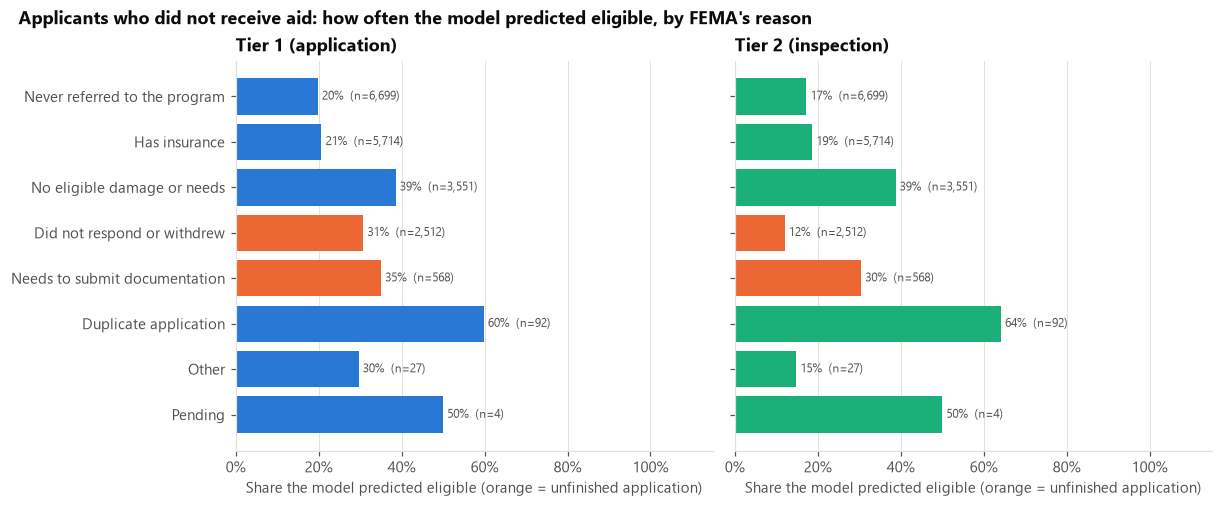

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained", sharey=True)
order = REASON["application"].index[::-1]
for ax, tier in zip(axes, TIERS):
    table = REASON[tier].reindex(order)
    y = np.arange(len(table))
    colors = [ORANGE if r in UNFINISHED_REASONS else TIER_COLORS[tier] for r in table.index]
    ax.barh(y, table["model predicted eligible"], color=colors)
    for yi, (_, r) in zip(y, table.iterrows()):
        ax.text(r["model predicted eligible"] + 0.01, yi, f"{r['model predicted eligible']:.0%}  (n={int(r['applicants']):,})",
                va="center", fontsize=8, color=INK_SOFT)
    ax.set_yticks(y, table.index)
    ax.set_xlim(0, 1.15)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_title(TIER_NAMES[tier])
    ax.set_xlabel("Share the model predicted eligible (orange = unfinished application)")
    ax.grid(axis="y", visible=False)
fig.suptitle("Applicants who did not receive aid: how often the model predicted eligible, by FEMA's reason",
             x=0.01, ha="left", fontweight="bold")
save_fig("false_positives_by_reason")
plt.show()

## Who does not finish the process
The share of each age and income group whose application ended as **did not respond or withdrew** or **needs to submit documentation**. This uses all applicants in the reporting split and does not depend on the model.

,applicants,unfinished,share unfinished
age,,,
<19,237,30,0.127
19-34,6852,736,0.107
35-49,9877,923,0.093
50-64,11490,807,0.070
65+,10441,584,0.056
All applicants,38897,3080,0.079


,applicants,unfinished,share unfinished
income,,,
0 (none reported),8751,1582,0.181
"<$15,000",2661,167,0.063
"$15,000-$30,000",6042,410,0.068
"$30,001-$60,000",10125,548,0.054
"$60,001-$120,000",7722,264,0.034
"$120,001-$175,000",2019,53,0.026
">$175,000",1577,56,0.036
All applicants,38897,3080,0.079


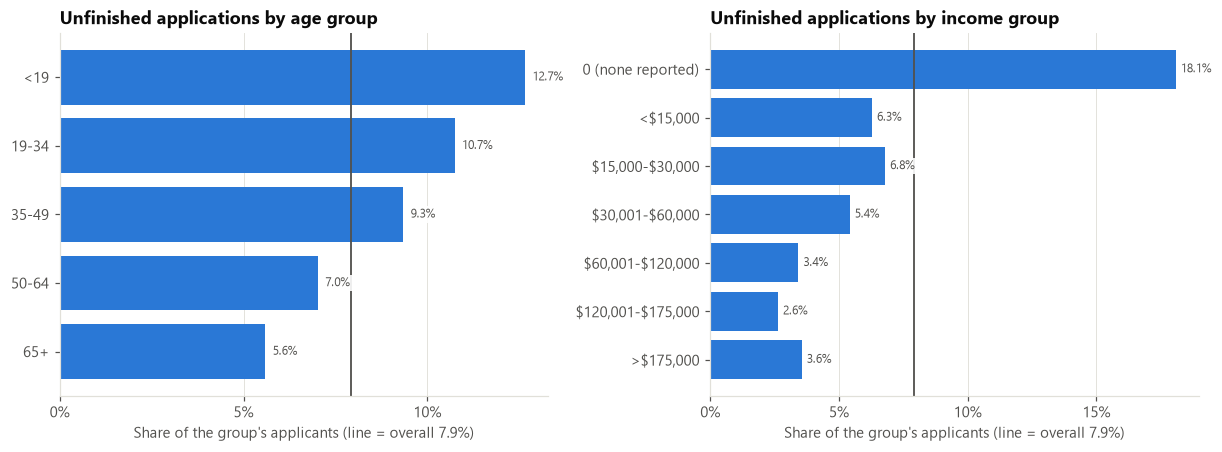

In [15]:
one_tier = pred[pred.tier == "application"].copy()
one_tier["unfinished"] = one_tier["reason"].isin(UNFINISHED_REASONS)

UNFINISHED = {}
for col in ["age", "income"]:
    table = one_tier.groupby(col, observed=False).agg(applicants=("unfinished", "size"),
                                                      unfinished=("unfinished", "sum"),
                                                      share_unfinished=("unfinished", "mean"))
    table.loc["All applicants"] = [len(one_tier), one_tier.unfinished.sum(), one_tier.unfinished.mean()]
    table[["applicants", "unfinished"]] = table[["applicants", "unfinished"]].astype(int)
    UNFINISHED[col] = table.rename(columns={"share_unfinished": "share unfinished"})
    display(UNFINISHED[col].round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for ax, col in zip(axes, ["age", "income"]):
    table = UNFINISHED[col]
    overall = table.loc["All applicants", "share unfinished"]
    groups = table.drop(index="All applicants")
    y = np.arange(len(groups))[::-1]
    ax.barh(y, groups["share unfinished"], color=BLUE)
    for yi, v in zip(y, groups["share unfinished"]):
        ax.text(v + 0.002, yi, f"{v:.1%}", va="center", fontsize=8, color=INK_SOFT, bbox=LABEL_BOX, zorder=4)
    ax.axvline(overall, color=INK_SOFT, lw=1.2)
    ax.xaxis.set_major_locator(plt.MultipleLocator(0.05))
    ax.set_yticks(y, tick_labels(groups.index))
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_title(f"Unfinished applications by {col} group")
    ax.set_xlabel(f"Share of the group's applicants (line = overall {overall:.1%})")
    ax.grid(axis="y", visible=False)
save_fig("unfinished_by_group")
plt.show()

### 📝 Analysis (Who is in the "not eligible" group)

_Draft from the validation-set run. Update the numbers after `REPORT_SPLIT` is switched to the test set._

**"Not eligible" is five different outcomes.** Of the 19,167 applicants in this split who did not receive aid, 35.0% were never referred to the program, 29.8% had insurance, 18.5% had no eligible damage or needs, 13.1% did not respond or withdrew, and 3.0% still owed documents.

**About one in five Tier 1 false positives is an unfinished application.** The model predicted "eligible" for 31% of applicants who did not respond or withdrew and for 35% of those who owed documents. Together that is 972 of the 4,914 false positives (19.8%). These households looked eligible on their application and then dropped out. They may not be model errors at all, and they are a list FEMA could follow up on.

**The inspection fields remove most of those.** On Tier 2 the model predicts "eligible" for only 12% of applicants who did not respond, down from 31%, and unfinished applications fall to 475 of 4,137 false positives (11.5%).

**The largest single source of false positives is "no eligible damage or needs"** (1,370 on Tier 1, 27.9%). The model predicts "eligible" for 39% of these applicants on both tiers. What the household reported looked like a qualifying case, and FEMA's review found otherwise.

**Younger applicants and applicants with no reported income finish less often.** Overall 7.9% of applications are unfinished. The share falls steadily with age, from 10.7% for ages 19-34 to 5.6% for ages 65+. For applicants with no income reported it is 18.1%, against 2.6% to 6.8% for every other income group.

This matters for the question the team raised about training only on completed applications: removing unfinished applications would remove younger applicants and applicants with no reported income more than others.

---
# Part 4: Business Value

The model is decision **support**. It never denies anyone aid, and a person makes every final decision.
Its value is in **sorting the queue**: telling caseworkers which applications are very likely to end in an award, which are very unlikely to, and which are uncertain and need a person first.

## What the predictions mean per 1,000 applications

In [16]:
rows = []
for tier in TIERS:
    df = pred[pred.tier == tier]
    n = len(df)
    counts = {
        "eligible, predicted eligible": ((df.y_true == 1) & (df.y_pred == 1)).sum(),
        "eligible, predicted NOT eligible (missed)": ((df.y_true == 1) & (df.y_pred == 0)).sum(),
        "not eligible, predicted eligible": ((df.y_true == 0) & (df.y_pred == 1)).sum(),
        "not eligible, predicted not eligible": ((df.y_true == 0) & (df.y_pred == 0)).sum(),
    }
    for label, count in counts.items():
        rows.append({"tier": TIER_NAMES[tier], "outcome": label, "applicants": count,
                     "per 1,000 applications": round(1000 * count / n)})
PER_1000 = pd.DataFrame(rows).set_index(["tier", "outcome"])
PER_1000

applicants  \
tier                 outcome                                                 
Tier 1 (application) eligible, predicted eligible                    17250   
                     eligible, predicted NOT eligible (missed)        2480   
                     not eligible, predicted eligible                 4914   
                     not eligible, predicted not eligible            14253   
Tier 2 (inspection)  eligible, predicted eligible                    18843   
                     eligible, predicted NOT eligible (missed)         887   
                     not eligible, predicted eligible                 4137   
                     not eligible, predicted not eligible            15030   

                                                                per 1,000 applications  
tier                 outcome                                                            
Tier 1 (application) eligible, predicted eligible                                  443  
                     eligible, predicted NOT eligible (missed)                      64  
                     not eligible, predicted eligible                              126  
                     not eligible, predicted not eligible                          366  
Tier 2 (inspection)  eligible, predicted eligible                                  484  
                     eligible, predicted NOT eligible (missed)                      23  
                     not eligible, predicted eligible                              106  
                     not eligible, predicted not eligible                          386

## Sorting the queue by confidence
Instead of one yes/no cut-off at 50%, FEMA could use the model's probability to make three piles:
- **Likely eligible** (probability at or above the upper cut-off): candidates for a fast track.
- **Likely not eligible** (probability at or below the lower cut-off): tell the household early what is usually missing, such as insurance documents.
- **Uncertain** (in between): a caseworker looks first.

For each pair of cut-offs the table shows how many applications land in each pile and how often the model is right there.

In [17]:
def triage(tier, low, high):
    df = pred[pred.tier == tier]
    likely, unlikely = df[df.prob >= high], df[df.prob <= low]
    middle = df[(df.prob > low) & (df.prob < high)]
    return {
        "tier": TIER_NAMES[tier], "cut-offs": f"{low:.0%} / {high:.0%}",
        "likely eligible: share of applications": len(likely) / len(df),
        "likely eligible: actually received aid": likely.y_true.mean(),
        "likely not eligible: share of applications": len(unlikely) / len(df),
        "likely not eligible: actually no aid": 1 - unlikely.y_true.mean(),
        "uncertain: share of applications": len(middle) / len(df),
        "eligible households in the 'not eligible' pile": int(unlikely.y_true.sum()),
    }


TRIAGE = pd.DataFrame([triage(tier, low, high) for tier in TIERS
                       for low, high in [(0.30, 0.70), (0.20, 0.80), (0.10, 0.90)]]).set_index(["tier", "cut-offs"])
TRIAGE.round(3).T

tier                                           Tier 1 (application)            \
cut-offs                                                  30% / 70% 20% / 80%   
likely eligible: share of applications                        0.421     0.250   
likely eligible: actually received aid                        0.830     0.886   
likely not eligible: share of applications                    0.358     0.305   
likely not eligible: actually no aid                          0.905     0.931   
uncertain: share of applications                              0.221     0.445   
eligible households in the 'not eligible' pile             1326.000   824.000   

tier                                                     Tier 2 (inspection)  \
cut-offs                                       10% / 90%           30% / 70%   
likely eligible: share of applications             0.105               0.453   
likely eligible: actually received aid             0.944               0.873   
likely not eligible: share of applications         0.220               0.378   
likely not eligible: actually no aid               0.962               0.971   
uncertain: share of applications                   0.675               0.170   
eligible households in the 'not eligible' pile   328.000             425.000   

tier                                                                
cut-offs                                       20% / 80% 10% / 90%  
likely eligible: share of applications             0.295     0.207  
likely eligible: actually received aid             0.940     0.978  
likely not eligible: share of applications         0.365     0.342  
likely not eligible: actually no aid               0.979     0.984  
uncertain: share of applications                   0.341     0.450  
eligible households in the 'not eligible' pile   301.000   216.000

## The trade-off when the cut-off moves
Moving the single yes/no cut-off trades one mistake for the other. A lower cut-off misses fewer eligible households but predicts eligible for more who are not.

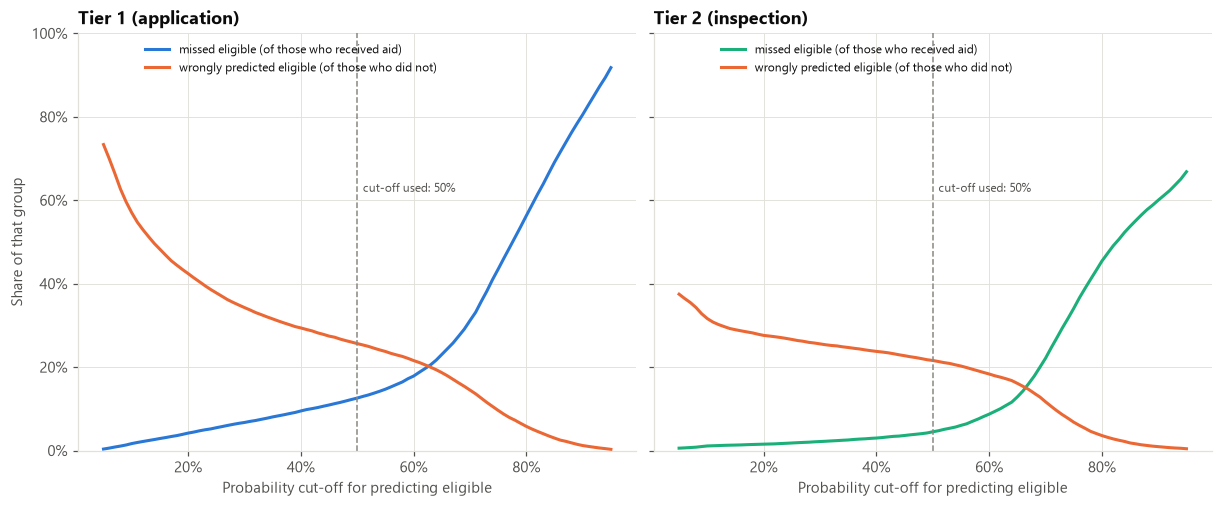

In [18]:
thresholds = np.linspace(0.05, 0.95, 91)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained", sharey=True)
for ax, tier in zip(axes, TIERS):
    df = pred[pred.tier == tier]
    elig, not_elig = df[df.y_true == 1].prob.values, df[df.y_true == 0].prob.values
    fnr = [(elig < t).mean() for t in thresholds]
    fpr = [(not_elig >= t).mean() for t in thresholds]
    ax.plot(thresholds, fnr, color=TIER_COLORS[tier], label="missed eligible (of those who received aid)")
    ax.plot(thresholds, fpr, color=ORANGE, label="wrongly predicted eligible (of those who did not)")
    ax.axvline(0.5, color=GRAY, lw=1, ls="--")
    ax.text(0.51, 0.62, "cut-off used: 50%", fontsize=8, color=INK_SOFT)
    ax.set_title(TIER_NAMES[tier])
    ax.set_xlabel("Probability cut-off for predicting eligible")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_ylim(0, 1)
    ax.legend(loc="upper left", bbox_to_anchor=(0.1, 1.0), fontsize=8)
axes[0].set_ylabel("Share of that group")
save_fig("threshold_tradeoff")
plt.show()

In [19]:
rows = []
for tier in TIERS:
    df = pred[pred.tier == tier]
    elig, not_elig = df[df.y_true == 1].prob, df[df.y_true == 0].prob
    for cut in [0.30, 0.40, 0.50, 0.60, 0.70]:
        rows.append({"tier": TIER_NAMES[tier], "cut-off": f"{cut:.0%}",
                     "missed eligible (FNR)": (elig < cut).mean(),
                     "wrongly eligible (FPR)": (not_elig >= cut).mean(),
                     "eligible households missed": int((elig < cut).sum()),
                     "wrongly predicted eligible": int((not_elig >= cut).sum())})
CUTOFFS = pd.DataFrame(rows).set_index(["tier", "cut-off"])
CUTOFFS.round(3)

missed eligible (FNR)  wrongly eligible (FPR)  \
tier                 cut-off                                                  
Tier 1 (application) 30%                      0.067                   0.343   
                     40%                      0.095                   0.294   
                     50%                      0.126                   0.256   
                     60%                      0.178                   0.216   
                     70%                      0.311                   0.145   
Tier 2 (inspection)  30%                      0.022                   0.256   
                     40%                      0.030                   0.238   
                     50%                      0.045                   0.216   
                     60%                      0.087                   0.183   
                     70%                      0.221                   0.117   

                              eligible households missed  \
tier                 cut-off                               
Tier 1 (application) 30%                            1326   
                     40%                            1871   
                     50%                            2480   
                     60%                            3521   
                     70%                            6143   
Tier 2 (inspection)  30%                             425   
                     40%                             590   
                     50%                             887   
                     60%                            1720   
                     70%                            4363   

                              wrongly predicted eligible  
tier                 cut-off                              
Tier 1 (application) 30%                            6568  
                     40%                            5632  
                     50%                            4914  
                     60%                            4133  
                     70%                            2777  
Tier 2 (inspection)  30%                            4899  
                     40%                            4554  
                     50%                            4137  
                     60%                            3516  
                     70%                            2239

### 📝 Analysis (Business value)

_Draft from the validation-set run. Update the numbers after `REPORT_SPLIT` is switched to the test set._

**Per 1,000 applications at registration (Tier 1),** the model sorts 809 correctly, misses 64 eligible households, and predicts "eligible" for 126 that do not receive aid. After inspection (Tier 2) it sorts 870 correctly, misses 23, and wrongly predicts "eligible" for 106.

**Three piles are more useful than one cut-off.** With cut-offs at 20% and 80%:
- **Tier 1:** 25.0% of applications land in the "likely eligible" pile and 88.6% of them received aid. Another 30.5% land in the "likely not eligible" pile and 93.1% of them did not. So on the day of registration the model can sort 55.5% of applications with about nine in ten correct, and it leaves 44.5% for a caseworker to look at first.
- **Tier 2:** 29.5% are "likely eligible" (94.0% correct) and 36.5% are "likely not eligible" (97.9% correct). That is 66.0% sorted, with 34.1% left as uncertain.

**The "likely not eligible" pile still contains eligible households:** 824 on Tier 1 and 301 on Tier 2 at these cut-offs. This is why that pile should trigger a message about what is usually missing, and never a denial.

**Moving the cut-off trades one mistake for the other.** Lowering the Tier 1 cut-off from 50% to 40% would miss 609 fewer eligible households (1,871 instead of 2,480) and wrongly predict "eligible" for 718 more (5,632 instead of 4,914). If FEMA judges that missing an eligible household is the worse mistake, a lower cut-off is the better setting. That choice belongs to FEMA, not to the model.

**Limits.** These numbers describe one storm in one county. Part of what the model learns is FEMA's own screening rules, so it shows how the process behaved, not who deserved aid.

---
# Part 5: Summary Against Our Success Criteria

In [20]:
rows = []
for tier in TIERS:
    df = pred[pred.tier == tier]
    worst = {}
    for col in ["age", "income"]:
        groups = FAIR[(tier, col)].drop(index="All applicants")
        groups = groups[groups["applicants"] >= MIN_GROUP_ROWS]
        worst[col] = groups["gap vs overall"].idxmax(), groups["gap vs overall"].max()
    rows.append({
        "tier": TIER_NAMES[tier],
        "ROC-AUC": roc_auc_score(df.y_true, df.prob),
        "accuracy": 1 - df.error.mean(),
        "overall error rate": df.error.mean(),
        "worst age group (gap)": f"{worst['age'][0]} ({100 * worst['age'][1]:+.1f} points)",
        "worst income group (gap)": f"{worst['income'][0]} ({100 * worst['income'][1]:+.1f} points)",
        "fairness target met": "yes" if max(worst["age"][1], worst["income"][1]) <= FAIRNESS_LIMIT else "NO",
    })
print(f"Scored on the {SPLIT_LABEL}. Fairness target: no group more than {100 * FAIRNESS_LIMIT:.0f} percentage points above the overall error rate "
      f"(groups under {MIN_GROUP_ROWS} applicants are not judged).")
pd.DataFrame(rows).set_index("tier").round(3).T

Scored on the validation set. Fairness target: no group more than 5 percentage points above the overall error rate (groups under 100 applicants are not judged).


tier,Tier 1 (application),Tier 2 (inspection)
ROC-AUC,0.88,0.938
accuracy,0.81,0.871
overall error rate,0.19,0.129
worst age group (gap),19-34 (+4.7 points),19-34 (+5.1 points)
worst income group (gap),"<$15,000 (+4.1 points)","<$15,000 (+3.2 points)"
fairness target met,yes,NO


### 📝 Analysis (Summary)

_Draft from the validation-set run. Update the numbers after `REPORT_SPLIT` is switched to the test set._

| Milestone 1 criterion | Result on this split |
|---|---|
| Fairness, Tier 1: no group more than 5 points above the overall error rate | **Met.** Largest gap 4.7 points (ages 19-34) |
| Fairness, Tier 2: same test | **Missed by 0.1 point.** Ages 19-34 are 5.1 points above |
| Income groups, both tiers | **Met.** Largest gap 4.1 points (under \$15,000, Tier 1) |

Three points for the report:
1. The model is close to the fairness limit on both tiers, and the group at the edge is the same one each time: applicants aged 19-34.
2. The gap is driven by predicting "eligible" too often for younger and lower-income applicants, which costs review time. The rate of missed eligible households is much more even.
3. A meaningful share of the "mistakes" are unfinished applications, which FEMA can act on.